# Exploratory Data Analysis (EDA) - Portfolio

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style='whitegrid')

# Load the dataset
file_path = '/content/portfolio.csv'
df = pd.read_csv(file_path)

# Display basic information
print('--- Dataset Info ---')
display(df.info())

print('\n--- First 5 Rows ---')
display(df.head())

print('\n--- Summary Statistics ---')
display(df.describe(include='all'))

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  10 non-null     int64 
 1   reward      10 non-null     int64 
 2   channels    10 non-null     object
 3   difficulty  10 non-null     int64 
 4   duration    10 non-null     int64 
 5   offer_type  10 non-null     object
 6   id          10 non-null     object
dtypes: int64(4), object(3)
memory usage: 692.0+ bytes


None


--- First 5 Rows ---


,Unnamed: 0,reward,channels,difficulty,duration,offer_type,id
0,0,10,"['email', 'mobile', 'social']",10,7,bogo,ae264e3637204a6fb9bb56bc8210ddfd
1,1,10,"['web', 'email', 'mobile', 'social']",10,5,bogo,4d5c57ea9a6940dd891ad53e9dbe8da0
2,2,0,"['web', 'email', 'mobile']",0,4,informational,3f207df678b143eea3cee63160fa8bed
3,3,5,"['web', 'email', 'mobile']",5,7,bogo,9b98b8c7a33c4b65b9aebfe6a799e6d9
4,4,5,"['web', 'email']",20,10,discount,0b1e1539f2cc45b7b9fa7c272da2e1d7



--- Summary Statistics ---


,Unnamed: 0,reward,channels,difficulty,duration,offer_type,id
count,10.00000,10.000000,10,10.000000,10.000000,10,10
unique,NaN,NaN,4,NaN,NaN,3,10
top,NaN,NaN,"['web', 'email', 'mobile', 'social']",NaN,NaN,bogo,ae264e3637204a6fb9bb56bc8210ddfd
freq,NaN,NaN,4,NaN,NaN,4,1
mean,4.50000,4.200000,NaN,7.700000,6.500000,NaN,NaN
std,3.02765,3.583915,NaN,5.831905,2.321398,NaN,NaN
min,0.00000,0.000000,NaN,0.000000,3.000000,NaN,NaN
25%,2.25000,2.000000,NaN,5.000000,5.000000,NaN,NaN
50%,4.50000,4.000000,NaN,8.500000,7.000000,NaN,NaN
75%,6.75000,5.000000,NaN,10.000000,7.000000,NaN,NaN


### Visualizing the Distributions
Let's write a script to automatically detect numeric and categorical columns and plot their respective distributions.

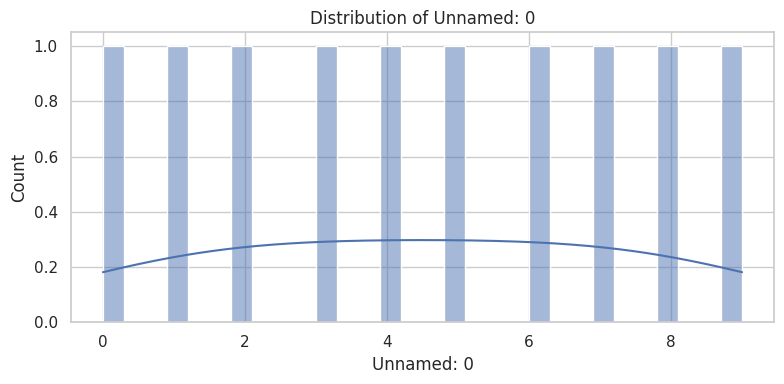

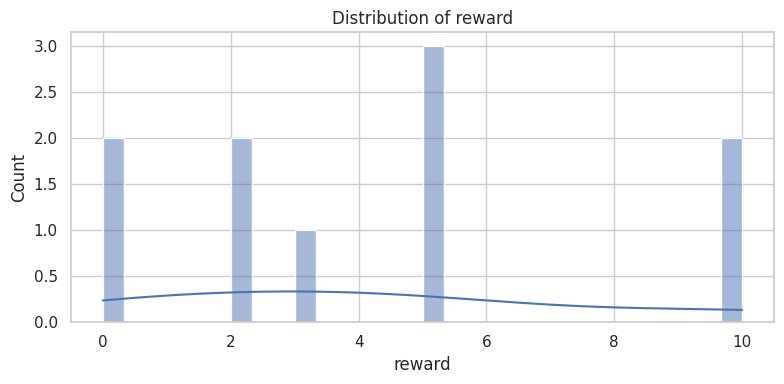

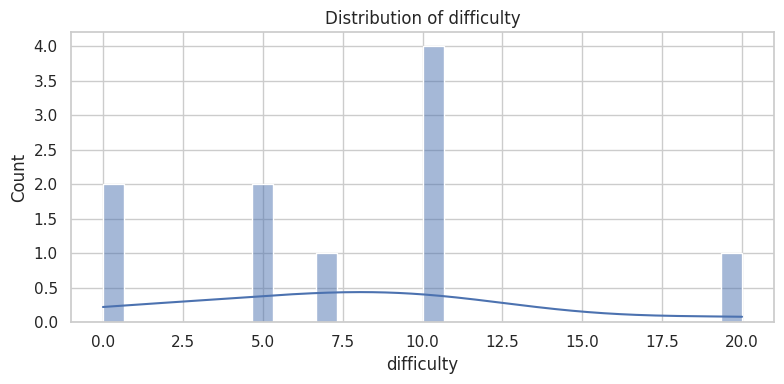

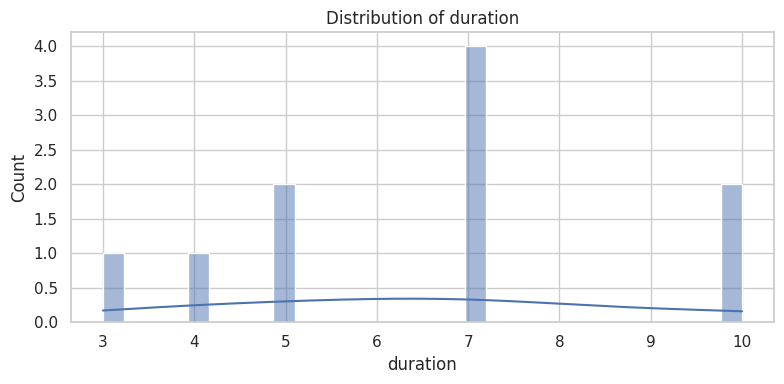

/tmp/ipykernel_938/2182651623.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=plot_data, y=col, order=plot_data[col].value_counts().index, palette='viridis')


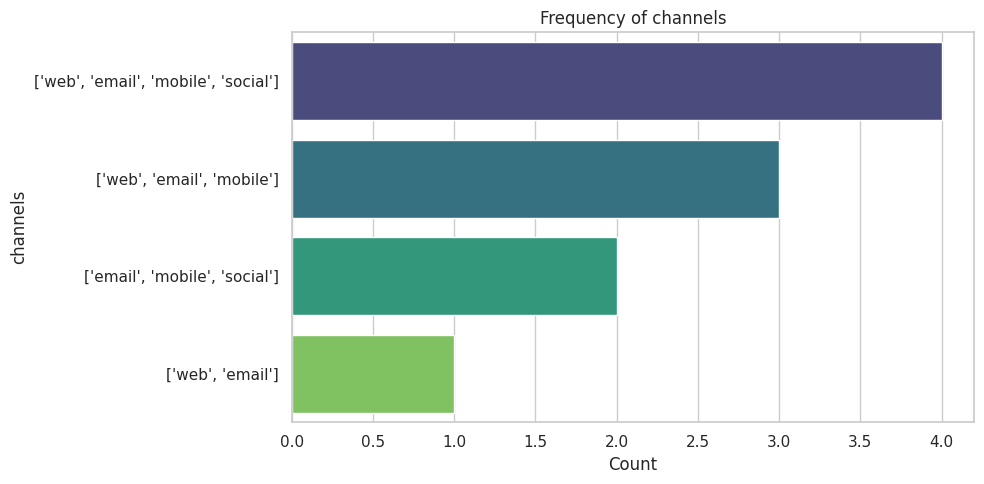

/tmp/ipykernel_938/2182651623.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=plot_data, y=col, order=plot_data[col].value_counts().index, palette='viridis')


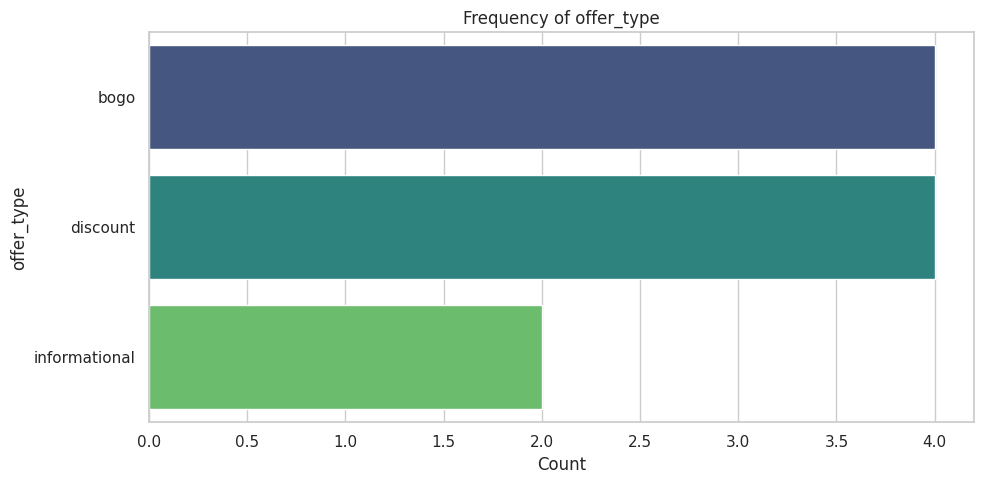

/tmp/ipykernel_938/2182651623.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=plot_data, y=col, order=plot_data[col].value_counts().index, palette='viridis')


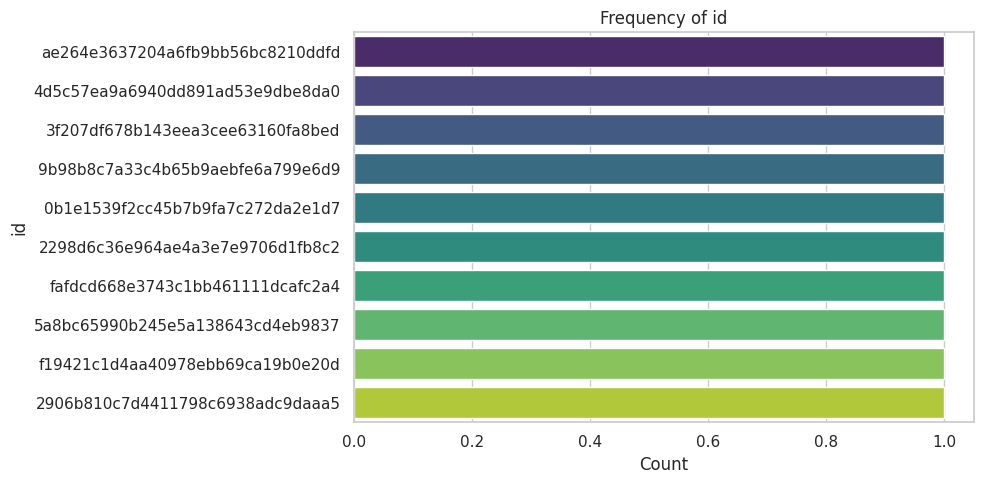

In [4]:
# Identify numeric and categorical columns
num_cols = df.select_dtypes(include=['number']).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Plot numeric distributions
for col in num_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col].dropna(), kde=True, bins=30)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.tight_layout()
    plt.show()

# Plot categorical distributions
for col in cat_cols:
    # If there are too many unique categories, only plot top 10
    if df[col].nunique() > 15:
        top_n = df[col].value_counts().head(10).index
        plot_data = df[df[col].isin(top_n)]
        title_suffix = ' (Top 10)'
    else:
        plot_data = df
        title_suffix = ''

    plt.figure(figsize=(10, 5))
    sns.countplot(data=plot_data, y=col, order=plot_data[col].value_counts().index, palette='viridis')
    plt.title(f'Frequency of {col}{title_suffix}')
    plt.xlabel('Count')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

### Correlation Heatmap (for Numeric Variables)
If there are multiple numeric columns, we can visualize how they correlate with each other.

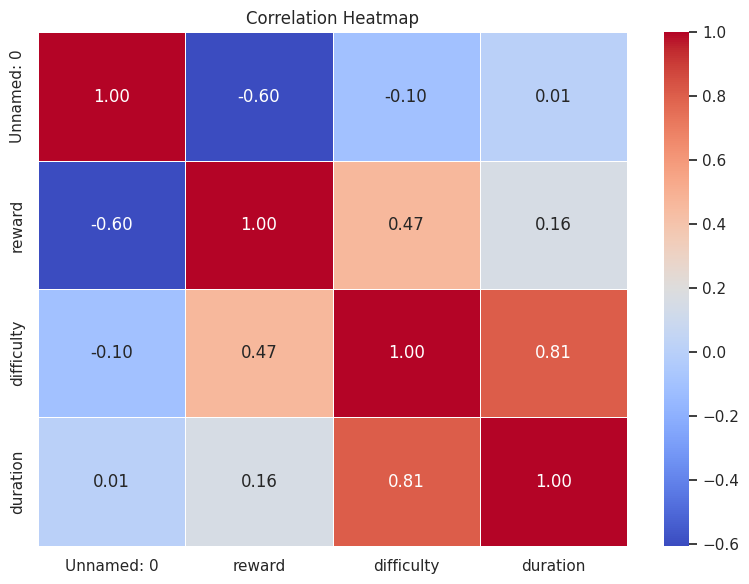

In [3]:
if len(num_cols) > 1:
    plt.figure(figsize=(8, 6))
    sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
    plt.title('Correlation Heatmap')
    plt.tight_layout()
    plt.show()
else:
    print('Not enough numeric columns to generate a correlation heatmap.')

### Distribution of Offer Types (Pie Chart)
Let's visualize the proportion of each offer type (`bogo`, `discount`, `informational`) in the portfolio.

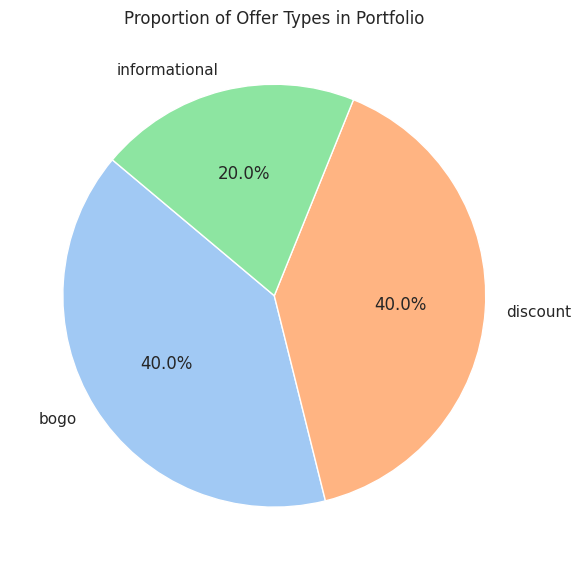

In [5]:
plt.figure(figsize=(6, 6))
offer_type_counts = df['offer_type'].value_counts()
plt.pie(
    offer_type_counts,
    labels=offer_type_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('pastel')[0:len(offer_type_counts)]
)
plt.title('Proportion of Offer Types in Portfolio')
plt.tight_layout()
plt.show()

## Machine Learning: Decision Tree Classifier
We will now prepare our portfolio data to train a Decision Tree Classifier. Since we want to predict the `offer_type` using other numerical properties (`reward`, `difficulty`, `duration`), we will split our data with an 80% training and 20% testing split.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Features and target
# We exclude the 'Unnamed: 0' and ID columns, focusing on numeric features.
X = df[['reward', 'difficulty', 'duration']]
y = df['offer_type']

# Split the dataset: 80% Training (8 samples), 20% Testing (2 samples)
# We remove stratify=y since we only have 2 test samples for 3 potential target classes
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Initialize and train Decision Tree
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)

# Make predictions
y_pred = clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f'Training Set Size: {len(X_train)} samples')
print(f'Testing Set Size: {len(X_test)} samples')
print(f'Accuracy on test set: {accuracy * 100:.1f}%')
print('\nClassification Report:')
print(classification_report(y_test, y_pred, zero_division=0))

Training Set Size: 8 samples
Testing Set Size: 2 samples
Accuracy on test set: 100.0%

Classification Report:
              precision    recall  f1-score   support

        bogo       1.00      1.00      1.00         2

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2



### Visualizing the Decision Tree
Let's visualize the trained decision tree rules.

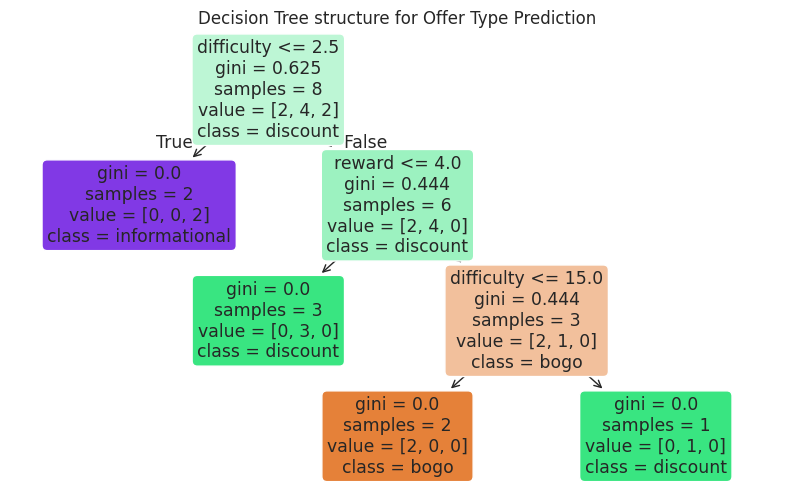

In [10]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Visualize the decision tree structure
plt.figure(figsize=(10, 6))
plot_tree(
    clf,
    feature_names=X.columns.tolist(),
    class_names=clf.classes_.tolist(),
    filled=True,
    rounded=True
)
plt.title('Decision Tree structure for Offer Type Prediction')
plt.show()

### Save the Trained Model
We will now serialize and save the trained Decision Tree model using python's built-in `pickle` library so it can be reloaded later.

In [11]:
import pickle

# Define the filename to save the model
model_filename = 'decision_tree_model.pkl'

# Save the model to disk
with open(model_filename, 'wb') as file:
    pickle.dump(clf, file)

print(f"Successfully saved the Decision Tree model to '{model_filename}'!")

Successfully saved the Decision Tree model to 'decision_tree_model.pkl'!
